# Channel detection, and the control test

Reproduces `figures/31_channel_separation.png`.

The question: can satellite imagery find a river that is no longer there?

A buried channel is filled with sand, which holds water better than the silt
around it, so the ground above stays damper into the dry season. That shows up
as darker soil in shortwave infrared and greener vegetation. The signal is weak
in any one image, so we stack several years and look for what recurs.

Nothing here is trained. We find the main axes of variation in the imagery and
then test, afterwards, whether they happen to line up with channel ground.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = pathlib.Path.cwd().parent
print('project root:', ROOT)

project root: /Users/vivek/Library/Mobile Documents/com~apple~CloudDocs/A School/Harvard/Thesis/Code


## 1. Build seasonal composites

Sentinel-2 is read straight from a public catalogue, only the window we need,
with cloud and shadow removed using the scene classification band that ships
with the imagery. We take a median per band per season: the median rather than
the mean because residual cloud edges are bright outliers.

Dry and wet are kept separate because the moisture contrast is strongest once
everything else has dried out.

In [2]:
from sat import stack

REGIONS = {
    'indus':   dict(bbox=[67.45, 24.70, 67.70, 24.92], label='Indus delta, Banbhore'),
    'periyar': dict(bbox=[76.15, 10.10, 76.40, 10.32], label='Periyar delta, Pattanam'),
}

composites = {}
for name, cfg in REGIONS.items():
    composites[name] = {
        season: stack.cached_composite(name, cfg['bbox'], '2022-01-01', '2024-12-31', season)[0]
        for season in ('dry', 'wet')
    }
    shp = composites[name]['dry']['red'].shape
    print(f"{name}: {shp[0]} x {shp[1]} pixels at 10 m")

indus: 2463 x 2553 pixels at 10 m


periyar: 2444 x 2748 pixels at 10 m


## 2. Score every pixel

Each pixel is now 24 numbers: eight bands and four derived ratios, twice over
for the two seasons. Principal components finds the directions along which
pixels differ most.

The first component is reliably overall brightness and carries nothing about
channels, so it is dropped. The score is the combined magnitude of the next
three. That rule was fixed before any control was run.

In [3]:
from sat import detect

scores = {}
for name in REGIONS:
    score, comps, evr, names, pick, alt = detect.spectral_score(composites[name])
    scores[name] = score
    print(f"{name}: variance explained by the first five components "
          f"{', '.join(f'{v:.2f}' for v in evr[:5])}")

indus: variance explained by the first five components 0.57, 0.25, 0.08, 0.04, 0.02


periyar: variance explained by the first five components 0.46, 0.33, 0.07, 0.05, 0.02


## 3. Define the control

The score means nothing until we check it against ground where we already know
the answer, with no judgement involved.

**Water** is identified by a physical property, not a decision: water absorbs
near-infrared almost completely, so `(green - NIR) / (green + NIR)` is positive
over water and negative over land.

**The test zone** is a ring of dry land two to twelve pixels outside the
waterline. The water itself is excluded deliberately, because otherwise the
detector could score well simply by rediscovering water, and what we actually
want is land that a channel has affected.

**The comparison group** is land at least 600 m from any water.

In [4]:
from sat import control

zones = {}
for name in REGIONS:
    med = composites[name]['dry']
    test_zone, water = control.riparian_control(med)
    far_from_water = (~ndimage.binary_dilation(water, iterations=60)
                      & np.isfinite(scores[name]) & ~test_zone)
    zones[name] = dict(test=test_zone, far=far_from_water, water=water)
    print(f"{name}: {test_zone.sum():,} pixels beside water, "
          f"{far_from_water.sum():,} well away from it")

indus: 415,077 pixels beside water, 4,243,568 well away from it


periyar: 550,661 pixels beside water, 2,808,383 well away from it


## 4. The test

Two bags of numbers: the scores of pixels beside water, and the scores of
pixels far from it. Pull one at random from each. How often is the first
bigger? That fraction is the AUC.

Half means the two bags are indistinguishable and the score carries no
information. The pass mark of 0.75 was fixed before any site was run.

In [5]:
rng = np.random.default_rng(0)
THRESHOLD = 0.75

def auc(score, group_a, group_b, n=40000):
    a = score[group_a & np.isfinite(score)]
    b = score[group_b]
    a = rng.choice(a, min(n, a.size), replace=False)
    b = rng.choice(b, min(n, b.size), replace=False)
    ranks = np.concatenate([a, b]).argsort().argsort() + 1.0
    return (ranks[:len(a)].sum() - len(a) * (len(a) + 1) / 2) / (len(a) * len(b)), a, b

results = {}
for name in REGIONS:
    value, a, b = auc(scores[name], zones[name]['test'], zones[name]['far'])
    results[name] = dict(auc=value, a=a, b=b)
    print(f"{name:9s} AUC = {value:.3f}   {'passes' if value >= THRESHOLD else 'fails'}")

indus     AUC = 0.814   passes
periyar   AUC = 0.578   fails


## 5. The figure

True colour, the score, and the two distributions side by side. If the detector
works the blue distribution sits to the right of the grey one; if it does not,
they pile on top of each other.

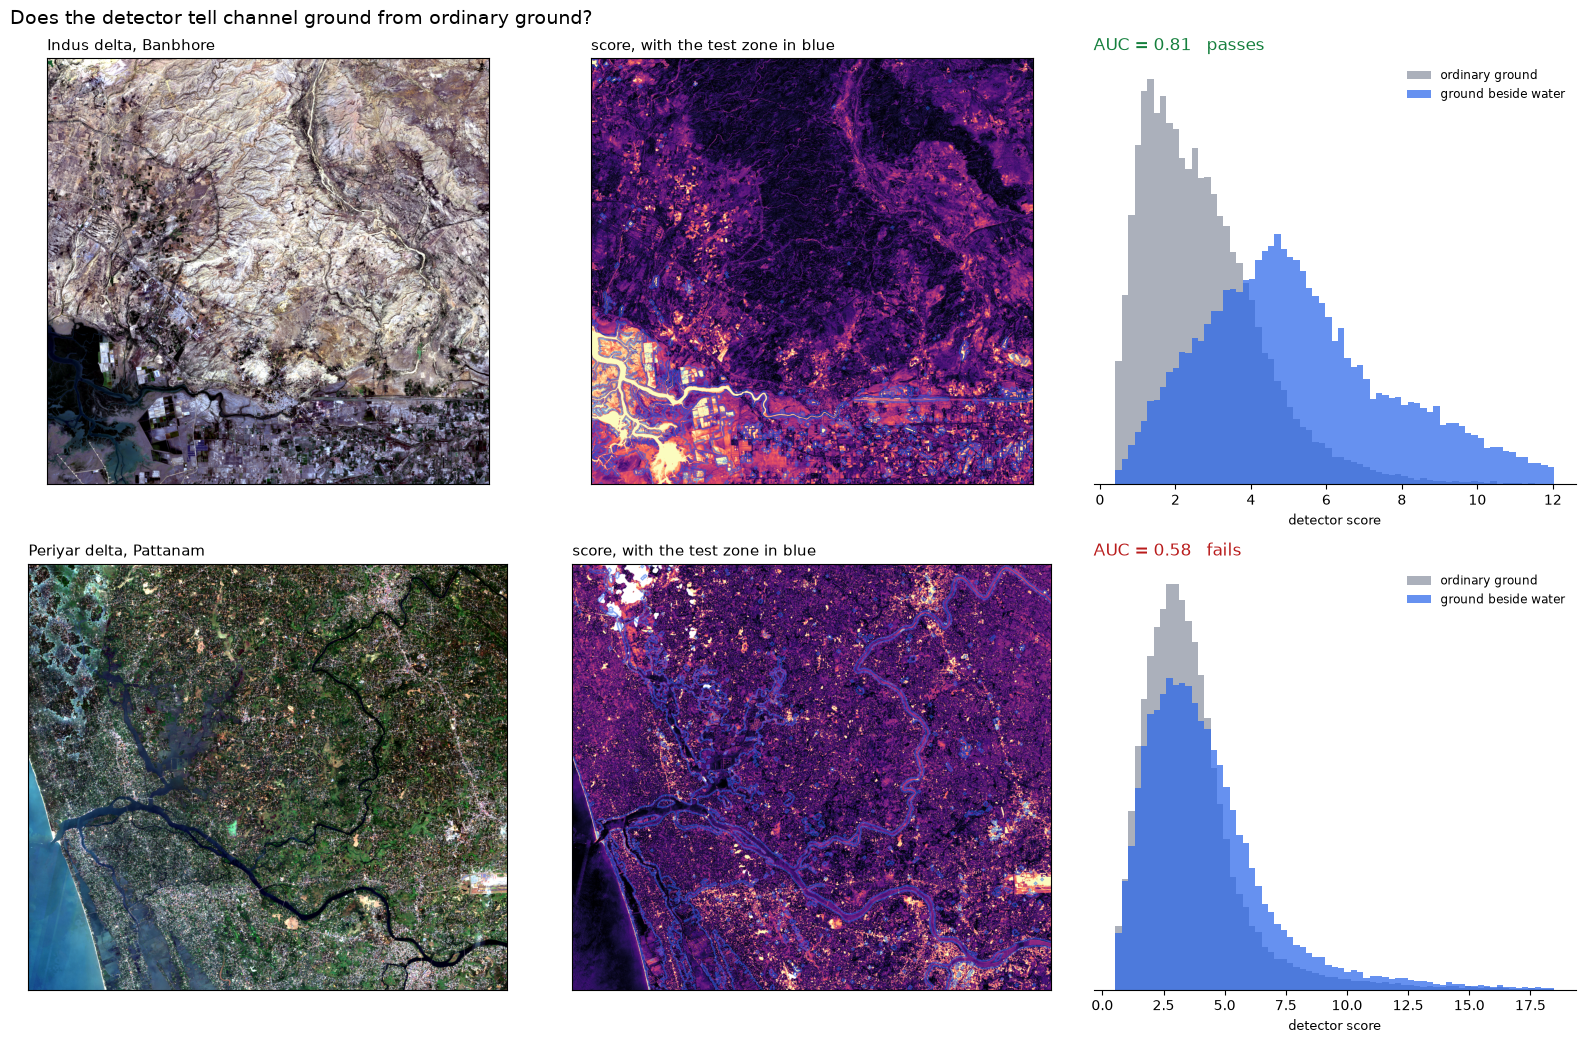

In [6]:
def stretch(a, lo=2, hi=98):
    v = a[np.isfinite(a)]
    p0, p1 = np.percentile(v, [lo, hi])
    return np.clip((a - p0) / (p1 - p0 + 1e-9), 0, 1)

fig, axes = plt.subplots(2, 3, figsize=(16, 10.6), gridspec_kw={'width_ratios': [1, 1, 0.92]})

for row, (name, cfg) in enumerate(REGIONS.items()):
    med = composites[name]['dry']
    axes[row, 0].imshow(np.dstack([stretch(med['red']), stretch(med['green']), stretch(med['blue'])]))
    axes[row, 0].set_title(cfg['label'], fontsize=10.5, loc='left')

    axes[row, 1].imshow(stretch(scores[name]), cmap='magma')
    overlay = np.zeros((*zones[name]['test'].shape, 4))
    overlay[zones[name]['test']] = [0.15, 0.39, 0.92, 0.55]
    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title('score, with the test zone in blue', fontsize=10.5, loc='left')

    r = results[name]
    lo, hi = np.percentile(np.concatenate([r['a'], r['b']]), [0.5, 99.5])
    bins = np.linspace(lo, hi, 70)
    ax = axes[row, 2]
    ax.hist(r['b'], bins=bins, color='#9ca3af', alpha=.85, density=True, label='ordinary ground')
    ax.hist(r['a'], bins=bins, color='#2563eb', alpha=.70, density=True, label='ground beside water')
    passed = r['auc'] >= THRESHOLD
    ax.set_title(f"AUC = {r['auc']:.2f}   {'passes' if passed else 'fails'}",
                 fontsize=12, loc='left', color='#15803d' if passed else '#b91c1c')
    ax.set_xlabel('detector score', fontsize=9)
    ax.set_yticks([]); ax.legend(fontsize=8.5, frameon=False)
    ax.spines[['top', 'right', 'left']].set_visible(False)

    for a_ in axes[row, :2]:
        a_.set_xticks([]); a_.set_yticks([])

fig.suptitle('Does the detector tell channel ground from ordinary ground?',
             fontsize=14, x=0.012, ha='left')
fig.tight_layout()
plt.show()

## What this does and does not establish

It establishes that the detector responds to ground beside a channel, strongly
in the arid Indus and not at all in Kerala, where the landscape is cut through
with paddy bunds and canals that produce the same linear damp signatures.

It does **not** establish that the detector finds a channel which is now
completely dry. The test zone sits beside water we can see. Testing the dry
case needs a buried channel somebody has already mapped.

One further caveat: the water index is itself one of the 24 inputs to the PCA,
so the score and the label are not fully independent. Re-running with it
removed would settle how much that matters.